# Phase 7.3 - Next Token Transformer v3.1 (Short Context + Walk-Forward)

Mejora aplicada:
- En vez de contexto largo (`seq_len=64`), usar contexto corto (`seq_len=16`).
- Evaluacion en **walk-forward** por periodos (3 folds temporales).

Motivacion:
- El contexto corto mejoro la deteccion de cambios de token sin perder precision global.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('.')

import importlib.util
script_path = ROOT / 'phases/phase07_online_detector/run_phase7_next_token_transformer_v3_1.py'
spec = importlib.util.spec_from_file_location('run_phase7_next_token_transformer_v3_1', script_path)
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
summary, fold_df, hist_df, pred_model_df, pred_base_df = mod.main()

OUT_DIR = ROOT / 'phases/phase07_online_detector/output_next_token_GBPUSD_v3_1'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_next_token_summary_v3_1.json'
FOLD_CSV = OUT_DIR / 'GBPUSD_next_token_fold_metrics_v3_1.csv'
HIST_CSV = OUT_DIR / 'GBPUSD_next_token_train_history_v3_1.csv'
PRED_MODEL_CSV = OUT_DIR / 'GBPUSD_next_token_fold_predictions_transformer_v3_1.csv'
PRED_BASE_CSV = OUT_DIR / 'GBPUSD_next_token_fold_predictions_baseline_v3_1.csv'

summary = json.loads(SUMMARY_JSON.read_text())
fold_df = pd.read_csv(FOLD_CSV)
hist_df = pd.read_csv(HIST_CSV)
pred_model_df = pd.read_csv(PRED_MODEL_CSV)
pred_base_df = pd.read_csv(PRED_BASE_CSV)

print('summary ->', SUMMARY_JSON)
print('fold metrics ->', FOLD_CSV)
print('history ->', HIST_CSV)
print('predictions model ->', PRED_MODEL_CSV)

Saved summary: ./phases/phase07_online_detector/output_next_token_GBPUSD_v3_1/GBPUSD_next_token_summary_v3_1.json
Mean metrics: {'baseline_top1_all': 0.9254858729381022, 'baseline_top3_all': 0.9532092111709947, 'baseline_top5_all': 0.9659616745604006, 'baseline_top3_change': 0.32454212454212455, 'model_top1_all': 0.9254858729381022, 'model_top3_all': 0.9659888943328433, 'model_top5_all': 0.9681120365833742, 'model_top1_change': 0.0, 'model_top3_change': 0.49010989010989015, 'model_top5_change': 0.5377289377289377}
summary -> ./phases/phase07_online_detector/output_next_token_GBPUSD_v3_1/GBPUSD_next_token_summary_v3_1.json
fold metrics -> ./phases/phase07_online_detector/output_next_token_GBPUSD_v3_1/GBPUSD_next_token_fold_metrics_v3_1.csv
history -> ./phases/phase07_online_detector/output_next_token_GBPUSD_v3_1/GBPUSD_next_token_train_history_v3_1.csv
predictions model -> ./phases/phase07_online_detector/output_next_token_GBPUSD_v3_1/GBPUSD_next_token_fold_predictions_transformer_v3_1.

In [2]:
# Cargar v2 para comparar
V2_SUMMARY = ROOT / 'phases/phase07_online_detector/output_next_token_GBPUSD_v2/GBPUSD_next_token_summary_v2.json'
summary_v2 = json.loads(V2_SUMMARY.read_text()) if V2_SUMMARY.exists() else None

print('v3.1 mean metrics:')
print(summary['mean_metrics'])
if summary_v2:
    print('\nv2 test metrics (single split):')
    print(summary_v2['transformer_test'])

v3.1 mean metrics:
{'baseline_top1_all': 0.9254858729381022, 'baseline_top3_all': 0.9532092111709947, 'baseline_top5_all': 0.9659616745604006, 'baseline_top3_change': 0.32454212454212455, 'model_top1_all': 0.9254858729381022, 'model_top3_all': 0.9659888943328433, 'model_top5_all': 0.9681120365833742, 'model_top1_change': 0.0, 'model_top3_change': 0.49010989010989015, 'model_top5_change': 0.5377289377289377}

v2 test metrics (single split):
{'loss': 0.5501268953084946, 'top1_all': 0.9152542372881356, 'top3_all': 0.9548022598870056, 'top5_all': 0.9717514124293786, 'n_change': 15, 'change_ratio': 0.0847457627118644, 'top1_change': 0.0, 'top3_change': 0.4666666666666667, 'top5_change': 0.6666666666666666}


In [3]:
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

display(fold_df)

# Mejoras promedio vs baseline en walk-forward
improv = {
    'delta_top1_all': float(fold_df['model_top1_all'].mean() - fold_df['baseline_top1_all'].mean()),
    'delta_top3_all': float(fold_df['model_top3_all'].mean() - fold_df['baseline_top3_all'].mean()),
    'delta_top5_all': float(fold_df['model_top5_all'].mean() - fold_df['baseline_top5_all'].mean()),
    'delta_top3_change': float(fold_df['model_top3_change'].mean() - fold_df['baseline_top3_change'].mean()),
}
print('Improvements (model - baseline):', improv)

,fold_id,n_train,n_val,n_test,baseline_top1_all,baseline_top3_all,baseline_top5_all,baseline_top1_change,baseline_top3_change,baseline_top5_change,model_top1_all,model_top3_all,model_top5_all,model_top1_change,model_top3_change,model_top5_change,model_test_loss,n_change_test,change_ratio_test
0,1,861,156,157,0.917197,0.936306,0.955414,0.0,0.230769,0.461538,0.917197,0.949045,0.949045,0.0,0.384615,0.384615,0.421454,13,0.082803
1,2,1017,157,157,0.955414,0.961783,0.974522,0.0,0.142857,0.428571,0.955414,0.968153,0.974522,0.0,0.285714,0.428571,0.252099,7,0.044586
2,3,1174,157,156,0.903846,0.961538,0.967949,0.0,0.600000,0.666667,0.903846,0.980769,0.980769,0.0,0.800000,0.800000,0.562238,15,0.096154


Improvements (model - baseline): {'delta_top1_all': 0.0, 'delta_top3_all': 0.012779683161848632, 'delta_top5_all': 0.002150362022973362, 'delta_top3_change': 0.16556776556776565}


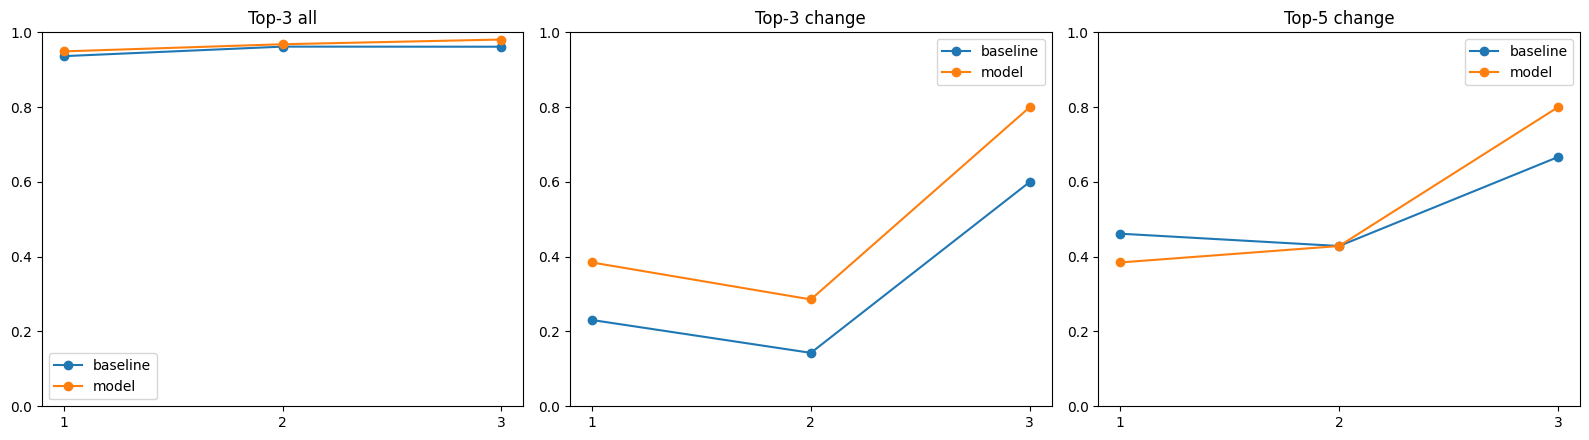

In [4]:
# Visual comparativo por fold
metrics_plot = [
    ('baseline_top3_all', 'model_top3_all', 'Top-3 all'),
    ('baseline_top3_change', 'model_top3_change', 'Top-3 change'),
    ('baseline_top5_change', 'model_top5_change', 'Top-5 change'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (bcol, mcol, title) in zip(axes, metrics_plot):
    x = fold_df['fold_id'].astype(str)
    ax.plot(x, fold_df[bcol], marker='o', label='baseline')
    ax.plot(x, fold_df[mcol], marker='o', label='model')
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.legend()
plt.tight_layout()
plt.show()

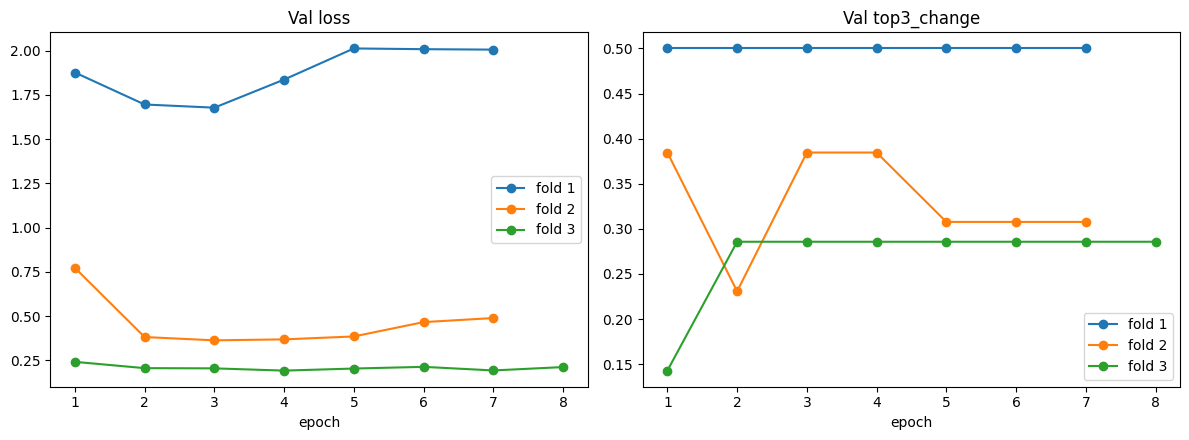

,fold_id,epoch,lr,train_loss,val_loss,train_top3_all,train_top3_change,val_top3_all,val_top3_change
0,1,1,0.0010,1.337470,1.876650,0.831591,0.837241,0.839744,0.500000
1,1,2,0.0010,0.315562,1.695965,0.983740,0.981030,0.846154,0.500000
2,1,3,0.0010,0.242844,1.678006,0.987224,0.986376,0.846154,0.500000
3,1,4,0.0010,0.221209,1.836691,0.990708,0.989247,0.846154,0.500000
4,1,5,0.0010,0.209929,2.012569,0.995354,0.994505,0.846154,0.500000
5,1,6,0.0005,0.204449,2.008399,0.989547,0.989305,0.846154,0.500000
6,1,7,0.0005,0.189157,2.005875,0.995354,0.994558,0.846154,0.500000
7,2,1,0.0010,1.420737,0.773199,0.820059,0.819398,0.949045,0.384615
8,2,2,0.0010,0.329114,0.382424,0.972468,0.971847,0.936306,0.230769
9,2,3,0.0010,0.253684,0.363813,0.982301,0.985177,0.949045,0.384615


In [5]:
# Curvas de entrenamiento por fold
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for fid, g in hist_df.groupby('fold_id'):
    axes[0].plot(g['epoch'], g['val_loss'], marker='o', label=f'fold {fid}')
    axes[1].plot(g['epoch'], g['val_top3_change'], marker='o', label=f'fold {fid}')

axes[0].set_title('Val loss')
axes[0].set_xlabel('epoch')
axes[0].legend()

axes[1].set_title('Val top3_change')
axes[1].set_xlabel('epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

display(hist_df.head(30))

In [6]:
# Ejemplos en eventos de cambio
pred_model_df['is_correct_top1'] = (pred_model_df['pred_token_id_top1'] == pred_model_df['target_token_id']).astype(int)
changes = pred_model_df[pred_model_df['is_change'] == 1].copy()
print('N change samples total:', len(changes))
display(changes[['fold_id','end_ts','last_token','target_token','pred_token_top1','pred_token_top2','pred_token_top3','is_correct_top1']].head(40))

N change samples total: 35


,fold_id,end_ts,last_token,target_token,pred_token_top1,pred_token_top2,pred_token_top3,is_correct_top1
2,1,2016-06-10 03:00:00,w11,w10,w11,w02,w10,0
17,1,2016-07-12 05:00:00,w10,w05,w10,w04,w11,0
40,1,2016-10-04 20:00:00,w05,w00,w05,w03,w08,0
63,1,2016-12-08 02:00:00,w00,w03,w00,w05,w02,0
65,1,2016-12-15 00:00:00,w03,w00,w03,w05,w02,0
68,1,2017-01-11 07:00:00,w00,w03,w00,w05,w02,0
81,1,2017-02-24 12:00:00,w03,w07,w03,w07,w02,0
82,1,2017-02-27 04:00:00,w07,w03,w07,w03,w02,0
83,1,2017-03-01 00:00:00,w03,w07,w03,w07,w02,0
86,1,2017-03-15 08:00:00,w07,w03,w07,w03,w02,0
